# How AI is Shaping Developers' Work and Careers

### 1. Business Understanding 

Artificial Intelligence tools are becoming common place in assisting with software development. This project explores how AI adoption affects developers careers using responses form the Stack Overflow Developer Survey. 

1. How does AI adoption vary across different career stages?
2. Is AI usage associated with differences in developer salary?
3. How does AI usage relate to developers' views of their career future?

In addition to exploratory analysis, a machine learning classification model will be 
developed to determine whether developer characteristics can help predict AI adoption.

### 2. Data Understanding and Exploratory Data Analysis

In [33]:
#import libraries 

import pandas as pd
#import shap as sp
import numpy as np
import sklearn 
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, root_mean_squared_error

In [34]:
#import the dataset

df = pd.read_csv('results.csv', low_memory=False)

The dataset is first inspected to understand its size, structure, data types, and 
available variables before making any cleaning or modeling decisions.

In [35]:
df.head()

,ResponseId,MainBranch,Age,EdLevel,Employment,EmploymentAddl,WorkExp,LearnCodeChoose,LearnCode,LearnCodeAI,...,AIAgentOrchestration,AIAgentOrchWrite,AIAgentObserveSecure,AIAgentObsWrite,AIAgentExternal,AIAgentExtWrite,AIHuman,AIOpen,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,25-34 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Employed,"Caring for dependents (children, elderly, etc.)",8.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,Vertex AI,NaN,NaN,NaN,ChatGPT,NaN,When I don’t trust AI’s answers,"Troubleshooting, profiling, debugging",61256.0,10.0
1,2,I am a developer by profession,25-34 years old,"Associate degree (A.A., A.S., etc.)",Employed,NaN,2.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I don’t trust AI’s answers;When I want to...,All skills. AI is a flop.,104413.0,9.0
2,3,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Independent contractor, freelancer, or self-em...",None of the above,10.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,ChatGPT;Claude Code;GitHub Copilot;Google Gemini,NaN,When I don’t trust AI’s answers;When I want to...,"Understand how things actually work, problem s...",53061.0,8.0
3,4,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Employed,None of the above,4.0,"Yes, I am not new to coding but am learning ne...","Other online resources (e.g. standard search, ...","Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,ChatGPT;Claude Code,NaN,When I don’t trust AI’s answers;When I want to...,NaN,36197.0,6.0
4,5,I am a developer by profession,35-44 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)","Independent contractor, freelancer, or self-em...","Caring for dependents (children, elderly, etc.)",21.0,"No, I am not new to coding and did not learn n...",NaN,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I don’t trust AI’s answers,"critical thinking, the skill to define the tas...",60000.0,7.0


In [36]:
df.shape

(49191, 172)

In [37]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49191 entries, 0 to 49190
Columns: 172 entries, ResponseId to JobSat
dtypes: float64(52), int64(1), object(119)
memory usage: 64.6+ MB


In [38]:
df.describe()

,ResponseId,WorkExp,YearsCode,TechEndorse_1,TechEndorse_2,TechEndorse_3,TechEndorse_4,TechEndorse_5,TechEndorse_6,TechEndorse_7,...,SO_Actions_3,SO_Actions_4,SO_Actions_5,SO_Actions_6,SO_Actions_9,SO_Actions_7,SO_Actions_10,SO_Actions_15,ConvertedCompYearly,JobSat
count,49191.000000,42893.000000,43042.000000,35975.000000,35975.000000,35975.000000,35975.000000,35975.000000,35975.000000,35975.000000,...,26260.000000,26260.000000,26260.000000,26260.000000,26260.000000,26260.000000,26260.000000,26260.000000,2.394700e+04,26670.000000
mean,24596.000000,13.367403,16.570861,7.867352,4.104211,4.110271,5.678193,4.119388,5.225990,6.477387,...,5.718355,4.561767,4.790861,5.199657,5.676314,4.984653,7.099505,10.079284,1.017615e+05,7.201950
std,14200.362883,10.800117,11.787610,2.397432,2.275821,2.329536,2.398084,2.437945,2.801045,2.331468,...,2.628016,3.070548,2.643177,2.563562,2.310659,2.490095,2.469394,1.940928,4.617569e+05,1.997245
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000e+00,0.000000
25%,12298.500000,5.000000,8.000000,7.000000,2.000000,2.000000,4.000000,2.000000,3.000000,5.000000,...,3.000000,1.000000,3.000000,3.000000,4.000000,3.000000,6.000000,10.000000,3.817100e+04,6.000000
50%,24596.000000,10.000000,14.000000,9.000000,4.000000,4.000000,6.000000,4.000000,5.000000,7.000000,...,6.000000,4.000000,5.000000,5.000000,6.000000,5.000000,8.000000,10.000000,7.532000e+04,8.000000
75%,36893.500000,20.000000,24.000000,9.000000,6.000000,6.000000,8.000000,6.000000,8.000000,8.000000,...,8.000000,7.000000,7.000000,7.000000,7.000000,7.000000,9.000000,10.000000,1.205960e+05,8.000000
max,49191.000000,100.000000,100.000000,14.000000,14.000000,14.000000,14.000000,14.000000,14.000000,14.000000,...,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,5.000000e+07,10.000000


In [39]:
#getting full list of columns 
list(df.columns)

['ResponseId',
 'MainBranch',
 'Age',
 'EdLevel',
 'Employment',
 'EmploymentAddl',
 'WorkExp',
 'LearnCodeChoose',
 'LearnCode',
 'LearnCodeAI',
 'AILearnHow',
 'YearsCode',
 'DevType',
 'OrgSize',
 'ICorPM',
 'RemoteWork',
 'PurchaseInfluence',
 'TechEndorseIntro',
 'TechEndorse_1',
 'TechEndorse_2',
 'TechEndorse_3',
 'TechEndorse_4',
 'TechEndorse_5',
 'TechEndorse_6',
 'TechEndorse_7',
 'TechEndorse_8',
 'TechEndorse_9',
 'TechEndorse_13',
 'TechEndorse_13_TEXT',
 'TechOppose_1',
 'TechOppose_2',
 'TechOppose_3',
 'TechOppose_5',
 'TechOppose_7',
 'TechOppose_9',
 'TechOppose_11',
 'TechOppose_13',
 'TechOppose_16',
 'TechOppose_15',
 'TechOppose_15_TEXT',
 'Industry',
 'JobSatPoints_1',
 'JobSatPoints_2',
 'JobSatPoints_3',
 'JobSatPoints_4',
 'JobSatPoints_5',
 'JobSatPoints_6',
 'JobSatPoints_7',
 'JobSatPoints_8',
 'JobSatPoints_9',
 'JobSatPoints_10',
 'JobSatPoints_11',
 'JobSatPoints_13',
 'JobSatPoints_14',
 'JobSatPoints_15',
 'JobSatPoints_16',
 'JobSatPoints_15_TEXT',
 

In [40]:
df["WorkExp"].describe()

count    42893.000000
mean        13.367403
std         10.800117
min          1.000000
25%          5.000000
50%         10.000000
75%         20.000000
max        100.000000
Name: WorkExp, dtype: float64

In [41]:
df["WorkExp"].value_counts(dropna=False).sort_index()

WorkExp
1.0      2453
2.0      2408
3.0      2613
4.0      2166
5.0      2563
         ... 
82.0        1
88.0        1
99.0        5
100.0      34
NaN      6298
Name: count, Length: 73, dtype: int64

In [42]:
df["AISelect"].value_counts(dropna=False)

AISelect
Yes, I use AI tools daily                      15883
NaN                                            15471
Yes, I use AI tools weekly                      5958
No, and I don't plan to                         5454
Yes, I use AI tools monthly or infrequently     4628
No, but I plan to soon                          1797
Name: count, dtype: int64

In [43]:
df["YearsCode"].describe()

count    43042.000000
mean        16.570861
std         11.787610
min          1.000000
25%          8.000000
50%         14.000000
75%         24.000000
max        100.000000
Name: YearsCode, dtype: float64

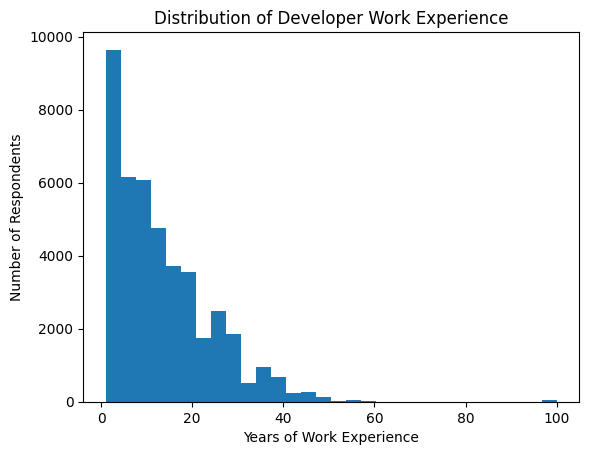

In [44]:
#Work Experience 

plt.hist(df['WorkExp'].dropna(), bins=30)
plt.xlabel('Years of Work Experience')
plt.ylabel('Number of Respondents')
plt.title('Distribution of Developer Work Experience')
plt.show()

The distribution of `WorkExp` is strongly right-skewed. Most respondents have 
approximately 1–20 years of professional work experience, while relatively few 
respondents report more than 40 years. A small number of extremely high values 
near 100 years are also present and require further investigation.

In [45]:
# Reviewing the age in regards to work experience
df.loc[
    df['WorkExp'] > 60,
    ['Age', 'WorkExp', 'YearsCode']
].sort_values('WorkExp')

,Age,WorkExp,YearsCode
10238,65 years or older,61.0,4.0
33407,65 years or older,61.0,30.0
38177,65 years or older,63.0,50.0
2520,65 years or older,65.0,65.0
23458,Prefer not to say,65.0,20.0
40501,65 years or older,65.0,60.0
48902,65 years or older,66.0,45.0
5430,65 years or older,68.0,55.0
19375,65 years or older,68.0,68.0
7940,25-34 years old,69.0,69.0


In [46]:
# Replace unrealistic WorkExp values above 60 with missing values

df.loc[df['WorkExp'] > 60, 'WorkExp'] = np.nan

In [47]:
df[df['WorkExp'] > 60]

,ResponseId,MainBranch,Age,EdLevel,Employment,EmploymentAddl,WorkExp,LearnCodeChoose,LearnCode,LearnCodeAI,...,AIAgentOrchestration,AIAgentOrchWrite,AIAgentObserveSecure,AIAgentObsWrite,AIAgentExternal,AIAgentExtWrite,AIHuman,AIOpen,ConvertedCompYearly,JobSat


Inspection of the extreme `WorkExp` values revealed several implausible responses. 
For example, some respondents aged 18–24 reported between 75 and 100 years of 
professional work experience. Because these values cannot reasonably represent 
professional experience, values greater than 60 were treated as invalid.

Rather than removing the respondents entirely, only the invalid `WorkExp` values 
were replaced with missing values (`NaN`) so that their responses to other survey 
questions could still be retained.

### 3 Data preparation 

In [48]:
#Creating a column to categorize different stages of Career
df['CareerStage'] = pd.cut(
    df['WorkExp'],
    bins=[0, 5, 10, 20, float('inf')],
    labels=[
        'Early Career',
        'Mid Career',
        'Experienced',
        'Highly Experienced'
    ]
)


Career stages were defined as:

- **Early Career:** 1–5 years
- **Mid Career:** 6–10 years
- **Experienced:** 11–20 years
- **Highly Experienced:** more than 20 years

In [49]:
df['CareerStage'].value_counts(dropna=False)

CareerStage
Early Career          12203
Experienced           12026
Mid Career             9654
Highly Experienced     8956
NaN                    6352
Name: count, dtype: int64

`AISelect` contains several responses describing how frequently respondents use AI 
tools. For this analysis, respondents who reported using AI daily, weekly, monthly, 
or infrequently were classified as **AI Users**.

Respondents who reported that they do not currently use AI were classified as 
**Non-AI Users**, including those who stated that they plan to use AI in the future. 
Missing responses were retained as missing values.

In [50]:
#Creating a column to classify AI adoption 
print(df['AISelect'].value_counts(dropna=False))
print("------------------------")

def group_ai_adoption(value):
    if pd.isna(value):
        return np.nan
    elif value.startswith('Yes'):
        return 'AI User'
    else:
        return 'Non-AI User'

df['AIAdoption'] = df['AISelect'].apply(group_ai_adoption)

print(df['AIAdoption'].value_counts(dropna=False))


AISelect
Yes, I use AI tools daily                      15883
NaN                                            15471
Yes, I use AI tools weekly                      5958
No, and I don't plan to                         5454
Yes, I use AI tools monthly or infrequently     4628
No, but I plan to soon                          1797
Name: count, dtype: int64
------------------------
AIAdoption
AI User        26469
NaN            15471
Non-AI User     7251
Name: count, dtype: int64


In [51]:
ai_by_career = pd.crosstab(
    df['CareerStage'],
    df['AIAdoption'],
    normalize='index'
) * 100

ai_by_career

AIAdoption,AI User,Non-AI User
CareerStage,,
Early Career,0.830677,0.169323
Mid Career,0.819225,0.180775
Experienced,0.791880,0.208120
Highly Experienced,0.713650,0.286350


### 
AI adoption declines as professional work experience increases. Approximately 83.1% 
of early-career respondents reported currently using AI tools, compared with 81.9% 
of mid-career respondents, 79.2% of experienced respondents, and 71.4% of highly 
experienced respondents.

The pattern suggests that developers earlier in their professional careers are more 
likely to report using AI tools than developers with longer professional experience. 

# graph here. 

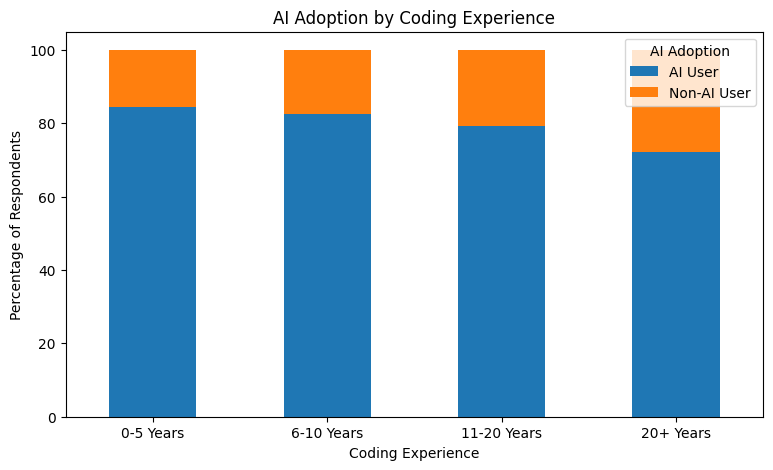

In [54]:
ai_by_career.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 5)
)

plt.title('AI Adoption by Career Stage')
plt.xlabel('Career Stage')
plt.ylabel('Percentage of Respondents')
plt.xticks(rotation=0)
plt.legend(title='AI Adoption')
plt.show()

In [55]:
from scipy.stats import chi2_contingency

In [56]:
contingency_table = pd.crosstab(
    df['CareerStage'],
    df['AIAdoption']
)

contingency_table

AIAdoption,AI User,Non-AI User
CodingExperience,,
0-5 Years,3887,715
6-10 Years,6477,1378
11-20 Years,8404,2202
20+ Years,7370,2841


In [57]:
from scipy.stats import chi2_contingency

chi2, p, dof, expected = chi2_contingency(contingency_table)

print("Chi-square:", chi2)
print("p-value:", p)
print("Degrees of freedom:", dof)

Chi-square: 415.8408122917318
p-value: 8.198967934598448e-90
Degrees of freedom: 3


In [58]:
alpha = 0.05

if p < alpha:
    print("There is a statistically significant relationship between career stage and AI adoption.")
else:
    print("There is not enough evidence to conclude that career stage and AI adoption are related.")

There is a statistically significant relationship between coding experience and AI adoption.


In [59]:
n = contingency_table.to_numpy().sum()
min_dim = min(contingency_table.shape) - 1

cramers_v = np.sqrt(chi2 / (n * min_dim))

print("Cramer's V:", cramers_v)

Cramer's V: 0.11179208319515231


The chi-square test was used to determine whether career stage and AI adoption were 
independent. The resulting p-value was below the 0.05 significance threshold, providing 
evidence of an association between career stage and AI adoption.

However, statistical significance does not necessarily imply a strong relationship. 
Cramér's V was therefore calculated to measure the strength of the association. The 
result indicates that the relationship between career stage and AI adoption is relatively 
weak, even though the difference is statistically significant.

# 4. Analyst of Research Questions
###  4.1 AI Adoption and Career Stage
###  4.2 AI Usage and Developer Salary
###  4.3 AI Usage and Career Outlook

5. Modeling and Evaluation
   Predict AI adoption

6. Prediction Scenario


7. Conclusions